# Chapitre 7 - Cours 3 : mises à jour perdues, write skew et fantômes

Ce notebook couvre la fin de la section *Weak Isolation Levels* : *Preventing Lost
Updates* (*Atomic write operations*, *Explicit locking*, *Automatically detecting lost
updates*, *Compare-and-set*, *Conflict resolution and
replication*) et *Write Skew and Phantoms* (*Characterizing write skew*, *More examples of
write skew*, *Phantoms causing write skew*, *Materializing conflicts*). Le cours 2 a
traité ce que voit un **lecteur** ; ici, deux transactions **écrivent** en même temps.

**Plan.**

1. La mise à jour perdue : le cycle lire-modifier-écrire.
2. Opérations d'écriture atomiques.
3. Verrouillage explicite (`SELECT ... FOR UPDATE`) et interblocages.
4. Détection automatique des mises à jour perdues.
5. Écriture conditionnelle (*compare-and-set*).
6. Réplication : résolution des conflits.
7. Le write skew : les médecins de garde.
8. Autres exemples ; les fantômes.
9. Matérialiser les conflits.
10. Récapitulatif expérimental : quel niveau empêche quoi ?

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import sqlite3

from ddia import transactions as tr
from ddia.transactions import (R, W, S, INC, RFU, SFU, run, plot_history, plot_precedence,
                               precedence_graph, simulate_load, LEVEL_LABELS)
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. La mise à jour perdue (section *Preventing Lost Updates*)

Le scénario le plus courant de conflit entre écrivains : l'application **lit** une
valeur, la **modifie** dans son code, et la **réécrit**. Si deux transactions le font en
même temps, la seconde écriture n'inclut pas la modification de la première, qui est
perdue (« écrasée »). Exemples : incrémenter un compteur ou un solde, ajouter un élément
à une liste dans un document JSON, deux personnes qui éditent la même page de wiki et
renvoient chacune la page entière.

Mesurons l'ampleur du problème : 200 transactions incrémentent le même compteur, avec au
plus $c$ transactions actives en même temps (ordonnancement aléatoire, une opération par
transaction et par tic). Les transactions abandonnées sont réessayées.

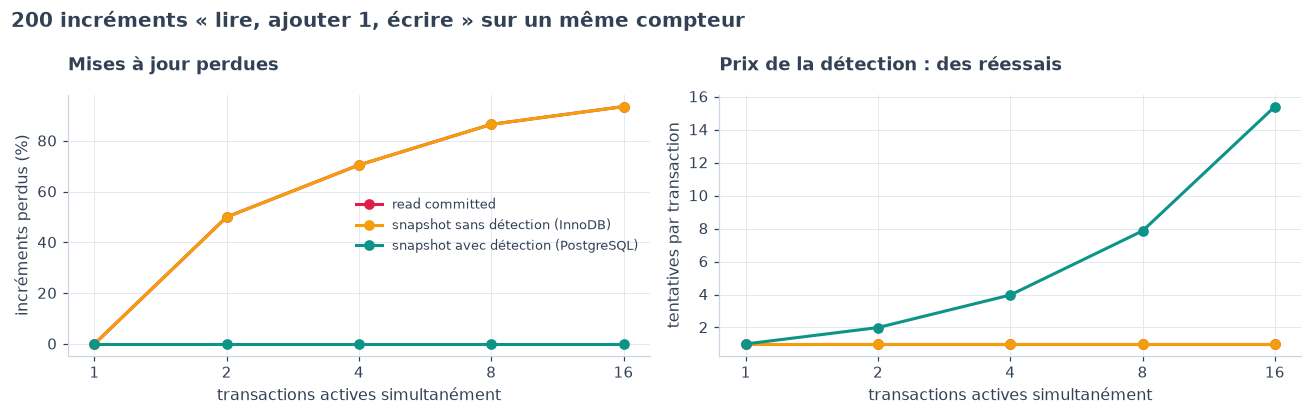

stratégie,read committed,snapshot avec détection (PostgreSQL),snapshot sans détection (InnoDB)
concurrence,,,
1,0,0,0
2,100,0,100
4,141,0,141
8,173,0,173
16,187,0,187


In [2]:
def incr_lu_ecrit(rng_, i):
    def prog():
        v = yield R("x")
        yield W("x", v + 1)
    return prog


conc = [1, 2, 4, 8, 16]
cas = {"read committed": dict(level="read_committed"),
       "snapshot sans détection (InnoDB)": dict(level="snapshot", detect_lost_updates=False),
       "snapshot avec détection (PostgreSQL)": dict(level="snapshot")}
lignes = []
for nom, kw in cas.items():
    for c in conc:
        out = simulate_load(incr_lu_ecrit, 200, concurrency=c, seed=1, initial={"x": 0}, **kw)
        lignes.append(dict(stratégie=nom, concurrence=c, perdues=200 - out["final"]["x"],
                           tentatives_par_tx=out["tentatives"] / 200))
perte = pd.DataFrame(lignes)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (nom, g), c in zip(perte.groupby("stratégie", sort=False), [ROSE, AMBER, TEAL]):
    axes[0].plot(g["concurrence"], g["perdues"] / 2, marker="o", color=c, label=nom)
    axes[1].plot(g["concurrence"], g["tentatives_par_tx"], marker="o", color=c, label=nom)
axes[0].set_ylabel("incréments perdus (%)")
axes[0].set_title("Mises à jour perdues")
axes[1].set_ylabel("tentatives par transaction")
axes[1].set_title("Prix de la détection : des réessais")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(conc); ax.set_xticklabels(conc)
    ax.set_xlabel("transactions actives simultanément")
axes[0].legend(fontsize=8.5)
finish(fig, "200 incréments « lire, ajouter 1, écrire » sur un même compteur")
plt.show()
perte.pivot(index="concurrence", columns="stratégie", values="perdues")

Dès deux transactions concurrentes, *read committed* et une snapshot isolation sans
détection perdent une fraction notable des incréments (leurs courbes se superposent :
dans ce scénario, chaque transaction lit au début et écrit juste après, si bien que
l'instantané et la dernière valeur validée coïncident), et la perte croît avec la
concurrence (à 16, l'immense majorité des incréments disparaît). La snapshot isolation
de PostgreSQL ne perd rien, mais au prix de nombreux réessais. Les sections suivantes
passent en revue les remèdes.

> **À retenir.** Lire, modifier dans l'application, puis réécrire n'est pas sûr sous les
> niveaux faibles : la perte est silencieuse et croît avec la concurrence.

## 2. Opérations d'écriture atomiques (section *Atomic write operations*)

Le meilleur remède, quand il s'applique : laisser la **base** faire la modification, en
une seule instruction, par exemple `UPDATE compteurs SET valeur = valeur + 1 WHERE cle =
'foo'`. MongoDB offre des modifications atomiques de parties d'un document, Redis des
opérations atomiques sur ses structures. L'implémentation prend un verrou exclusif sur
l'objet pendant la lecture-modification (ou exécute toutes ces opérations sur un seul
fil). L'opération `INC` du moteur fait exactement cela.

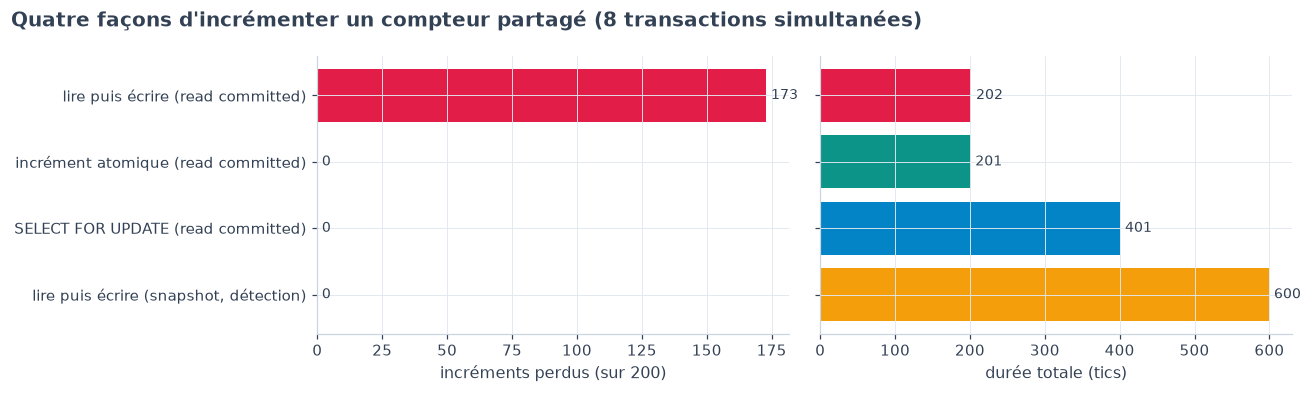

,incréments_perdus,tentatives,tics,attentes
stratégie,,,,
lire puis écrire (read committed),173,200,202,1073
incrément atomique (read committed),0,200,201,1282
SELECT FOR UPDATE (read committed),0,200,401,1372
"lire puis écrire (snapshot, détection)",0,1572,600,1372


In [3]:
def incr_atomique(rng_, i):
    def prog():
        yield INC("x")
    return prog


def incr_for_update(rng_, i):
    def prog():
        v = yield RFU("x")
        yield W("x", v + 1)
    return prog


strategies = {
    "lire puis écrire (read committed)": (incr_lu_ecrit, dict(level="read_committed")),
    "incrément atomique (read committed)": (incr_atomique, dict(level="read_committed")),
    "SELECT FOR UPDATE (read committed)": (incr_for_update, dict(level="read_committed")),
    "lire puis écrire (snapshot, détection)": (incr_lu_ecrit, dict(level="snapshot")),
}
res_strat = []
for nom, (prog, kw) in strategies.items():
    out = simulate_load(prog, 200, concurrency=8, seed=2, initial={"x": 0}, **kw)
    res_strat.append(dict(stratégie=nom, incréments_perdus=200 - out["final"]["x"],
                          tentatives=out["tentatives"], tics=out["tics"], attentes=out["attentes"]))
res_strat = pd.DataFrame(res_strat).set_index("stratégie")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
cols = [ROSE, TEAL, SKY, AMBER]
axes[0].barh(res_strat.index, res_strat["incréments_perdus"], color=cols)
axes[0].set_xlabel("incréments perdus (sur 200)")
axes[1].barh(res_strat.index, res_strat["tics"], color=cols)
axes[1].set_xlabel("durée totale (tics)")
axes[1].set_yticklabels([])
for ax in axes:
    ax.invert_yaxis()
    annotate_bars(ax, "{:.0f}")
finish(fig, "Quatre façons d'incrémenter un compteur partagé (8 transactions simultanées)")
plt.show()
res_strat

L'incrément atomique ne perd rien, ne provoque aucun abandon et finit le plus vite : la
lecture et l'écriture tiennent en une opération, le verrou est tenu brièvement. Le
`SELECT FOR UPDATE` est correct aussi mais fait **attendre** les autres transactions
pendant tout le cycle lire-modifier-écrire. La snapshot isolation avec détection est
correcte mais gaspille des tentatives. Le livre met en garde contre les ORM, qui
génèrent facilement des cycles lire-modifier-écrire dangereux au lieu des opérations
atomiques de la base.

> **À retenir.** Si la modification s'exprime comme une opération de la base (incrément,
> ajout à une liste...), c'est le remède le plus simple et le plus rapide.

## 3. Verrouillage explicite (section *Explicit locking*)

Quand la logique ne tient pas dans une opération atomique (le livre prend un jeu
multijoueur où un déplacement doit respecter les règles du jeu), l'application peut
**verrouiller explicitement** les lignes qu'elle va modifier : `SELECT ... FOR UPDATE`.
Toute autre transaction qui veut les verrouiller ou les modifier attend la fin du cycle.
Deux dangers : **oublier** un verrou quelque part dans le code, et l'**interblocage**
quand plusieurs objets sont verrouillés dans des ordres différents. Rejouons-le : deux
joueurs déplacent chacun deux pièces, mais dans l'ordre inverse.

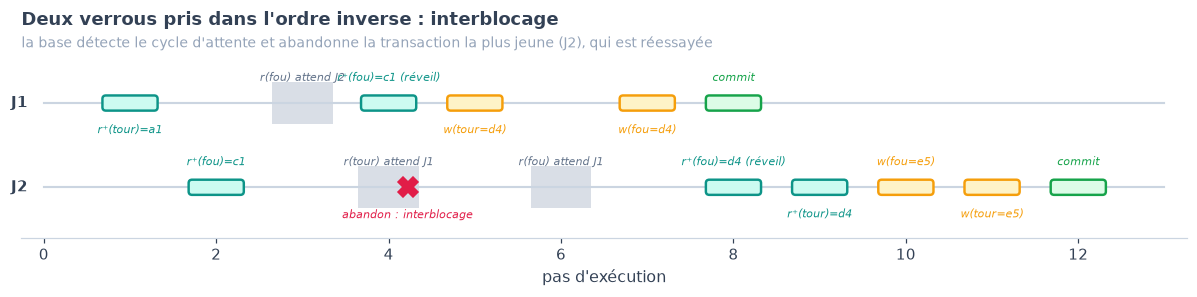

In [4]:
def deplace(p1, p2, case):
    def prog():
        yield RFU(p1)
        yield RFU(p2)
        yield W(p1, case)
        yield W(p2, case)
    return prog


r = run({"tour": "a1", "fou": "c1"}, {"J1": deplace("tour", "fou", "d4"), "J2": deplace("fou", "tour", "e5")},
        "J1 J2 J1 J2".split(), level="read_committed", retries=1)
plot_history(r, title="Deux verrous pris dans l'ordre inverse : interblocage",
             subtitle="la base détecte le cycle d'attente et abandonne la transaction la plus jeune (J2), qui est réessayée",
             width=11).show()

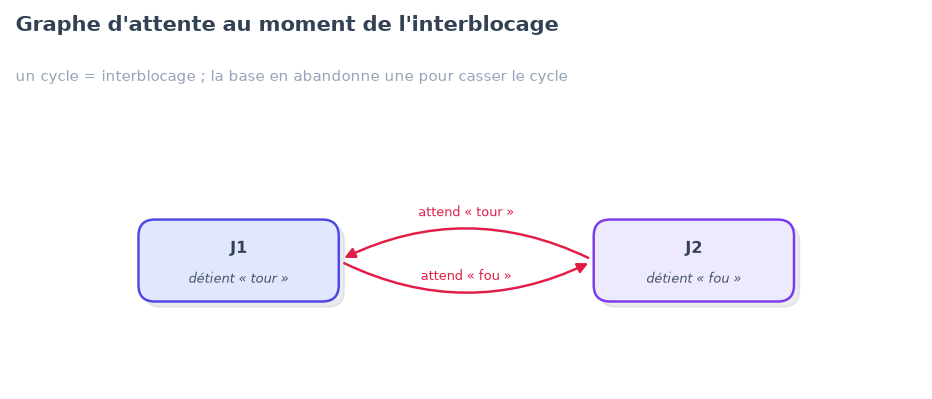

In [5]:
g = nx.DiGraph()
g.add_edge("J1", "J2", label="attend « fou »")
g.add_edge("J2", "J1", label="attend « tour »")
d = Diagram(10, 3.2, title="Graphe d'attente au moment de l'interblocage",
            subtitle="un cycle = interblocage ; la base en abandonne une pour casser le cycle")
d.box("J1", 2.5, 1.4, "J1", sub="détient « tour »", color=INDIGO, w=2.2)
d.box("J2", 7.5, 1.4, "J2", sub="détient « fou »", color=VIOLET, w=2.2)
d.arrow("J1", "J2", "attend « fou »", rad=0.25, color=ROSE)
d.arrow("J2", "J1", "attend « tour »", rad=0.25, color=ROSE)
d.show()

Le moteur détecte l'interblocage en cherchant un cycle dans le **graphe d'attente**
(qui attend qui) et abandonne la transaction la plus jeune ; celle-ci est réessayée et
réussit. C'est ce que font la plupart des bases (PostgreSQL vérifie après un court délai,
`deadlock_timeout`). Le remède classique côté application : toujours verrouiller dans un
**ordre canonique** (par exemple par identifiant croissant).

> **À retenir.** `SELECT ... FOR UPDATE` rend sûr un cycle lire-modifier-écrire
> arbitraire, au prix d'attentes et d'interblocages possibles ; il faut penser à le
> mettre partout où c'est nécessaire.

## 4. Détection automatique des mises à jour perdues (section *Automatically detecting lost updates*)

Autre approche : laisser les cycles s'exécuter en parallèle, et **détecter** la mise à
jour perdue pour abandonner la transaction fautive, qui sera réessayée. Cela s'intègre
bien à la snapshot isolation : au moment d'écrire une ligne, si sa dernière version
validée a été créée par une transaction **concurrente** (invisible dans l'instantané), il
y a conflit. PostgreSQL (`REPEATABLE READ`), Oracle (`SERIALIZABLE`) et SQL Server
(`SNAPSHOT`) le font ; MySQL/InnoDB en `REPEATABLE READ` ne le fait pas, ce qui, selon
certains auteurs, l'empêche d'être une vraie snapshot isolation.

Avantage majeur : l'application n'a **rien** à faire de spécial (pas d'oubli possible),
sinon réessayer les transactions abandonnées. Comparons les deux variantes sur le
scénario de la section 1 du cours 1 (deux incréments, ordre `ABABAB`).

In [6]:
def _incr():
    v = yield R("x")
    yield W("x", v + 1)


rows = []
for nom, kw in [("snapshot sans détection (InnoDB)", dict(detect_lost_updates=False)),
                ("snapshot avec détection (PostgreSQL)", dict())]:
    r = run({"x": 42}, {"A": _incr, "B": _incr}, "ABABAB", level="snapshot", **kw)
    r2 = run({"x": 42}, {"A": _incr, "B": _incr}, "ABABAB", level="snapshot", retries=1, **kw)
    rows.append(dict(variante=nom, issue_A=r.outcomes["A"], issue_B=r.outcomes["B"],
                     valeur_finale=r.final["x"], avec_un_réessai=r2.final["x"]))
pd.DataFrame(rows).set_index("variante")

,issue_A,issue_B,valeur_finale,avec_un_réessai
variante,,,,
snapshot sans détection (InnoDB),commit,commit,43,43
snapshot avec détection (PostgreSQL),commit,abort (mise à jour concurrente de x (par A)),43,44


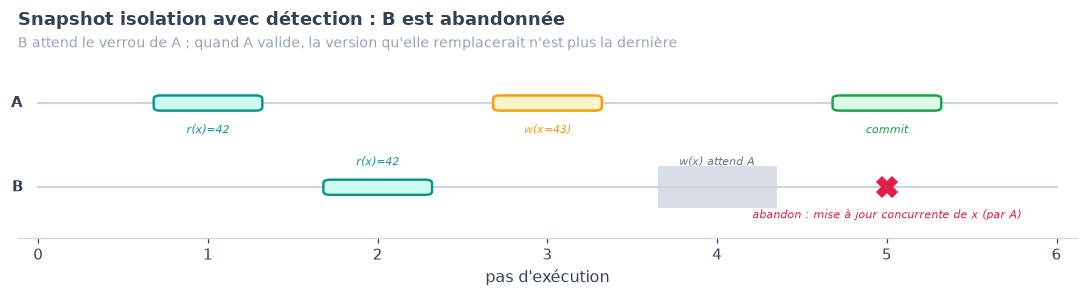

In [7]:
r = run({"x": 42}, {"A": _incr, "B": _incr}, "ABABAB", level="snapshot")
plot_history(r, title="Snapshot isolation avec détection : B est abandonnée",
             subtitle="B attend le verrou de A ; quand A valide, la version qu'elle remplacerait n'est plus la dernière",
             width=10).show()

Sans détection, les deux transactions valident et la valeur finale est 43 : la mise à
jour de A est perdue. Avec détection, B est abandonnée (« mise à jour concurrente ») ;
réessayée, elle relit 43 et écrit 44.

> **À retenir.** La détection automatique est la solution la moins sujette aux erreurs
> humaines ; elle exige seulement de réessayer les transactions abandonnées. Vérifiez si
> votre base la fait.

## 5. Écriture conditionnelle, *compare-and-set* (section *Compare-and-set*)

Dans les bases sans transactions, on trouve souvent une **écriture conditionnelle** :
l'écriture n'a lieu que si la valeur n'a pas changé depuis qu'on l'a lue (comme
l'instruction CAS des processeurs). Par exemple `UPDATE wiki SET contenu = 'nouveau'
WHERE id = 1234 AND contenu = 'ancien'`, ou mieux avec un **numéro de version** incrémenté
à chaque écriture (« verrouillage optimiste »). Si la condition échoue, on relit et on
recommence.

Le livre signale un piège : sous MVCC, la clause `WHERE` d'un `UPDATE` voit souvent la
dernière version validée (exception aux règles de visibilité), ce qui est le
comportement voulu ; mais selon l'implémentation, la condition peut être évaluée sur un
instantané ancien, et la protection disparaît.

Implémentons un petit magasin clé-valeur à versions et mesurons le nombre de tentatives
quand $n$ clients font chacun un incrément par CAS, avec un entrelacement aléatoire de
leurs lectures et de leurs écritures conditionnelles.

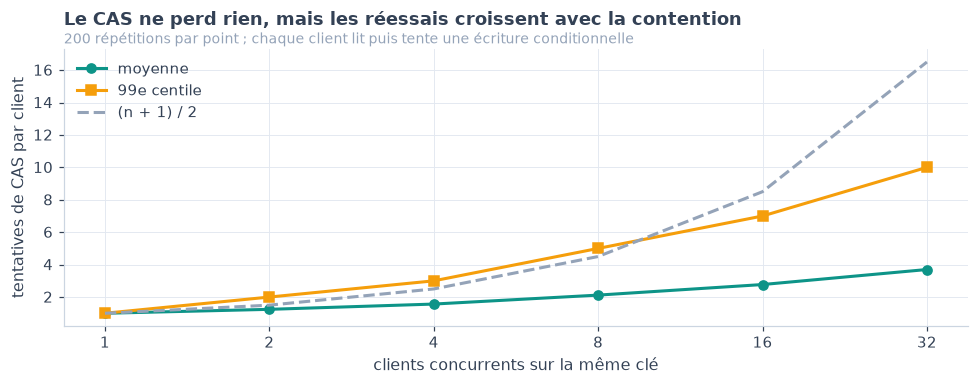

In [8]:
class MagasinCAS:
    def __init__(self):
        self.valeur, self.version = 0, 0

    def lire(self):
        return self.valeur, self.version

    def cas(self, version_attendue, nouvelle):
        if self.version != version_attendue:
            return False
        self.valeur, self.version = nouvelle, self.version + 1
        return True


def incrementer_par_cas(n_clients, g):
    m = MagasinCAS()
    lu = {}
    tentatives = {c: 0 for c in range(n_clients)}
    en_cours = list(range(n_clients))
    while en_cours:
        c = en_cours[g.integers(len(en_cours))]
        if c not in lu:
            lu[c] = m.lire()
        else:
            v, ver = lu.pop(c)
            tentatives[c] += 1
            if m.cas(ver, v + 1):
                en_cours.remove(c)
    return m.valeur, list(tentatives.values())


g = np.random.default_rng(3)
stats = []
for n in [1, 2, 4, 8, 16, 32]:
    tent = []
    for _ in range(200):
        val, t = incrementer_par_cas(n, g)
        assert val == n          # aucune mise à jour perdue
        tent += t
    stats.append(dict(clients=n, moyenne=np.mean(tent), p99=np.percentile(tent, 99), max=max(tent)))
stats = pd.DataFrame(stats)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(stats["clients"], stats["moyenne"], marker="o", color=TEAL, label="moyenne")
ax.plot(stats["clients"], stats["p99"], marker="s", color=AMBER, label="99e centile")
ax.plot(stats["clients"], (stats["clients"] + 1) / 2, ls="--", color=GRAY, label="(n + 1) / 2")
ax.set_xscale("log", base=2); ax.set_xticks(stats["clients"]); ax.set_xticklabels(stats["clients"])
ax.set_xlabel("clients concurrents sur la même clé")
ax.set_ylabel("tentatives de CAS par client")
ax.set_title("Le CAS ne perd rien, mais les réessais croissent avec la contention")
subtitle(ax, "200 répétitions par point ; chaque client lit puis tente une écriture conditionnelle")
ax.legend()
plt.tight_layout(); plt.show()

Le CAS ne perd jamais d'incrément (l'assertion le vérifie), mais le nombre moyen de
tentatives croît à peu près linéairement avec le nombre de clients (proche de
$(n+1)/2$ : en moyenne, la moitié des concurrents réussissent avant vous), et la queue de
distribution est longue. C'est la marque de toutes les approches **optimistes** (on
retrouvera ce compromis avec SSI au cours 4).

> **À retenir.** L'écriture conditionnelle (valeur ou numéro de version attendu) est un
> verrouillage optimiste sur un seul objet : parfait à faible contention, coûteux en
> réessais à forte contention.

## 6. Réplication : résolution des conflits (section *Conflict resolution and replication*)

Verrous et CAS supposent **une seule copie à jour** de la donnée. Avec une réplication
multi-leader ou sans leader (chapitre 5), plusieurs répliques acceptent
des écritures concurrentes et les propagent de façon asynchrone : ces techniques ne
s'appliquent plus. On laisse alors les écritures concurrentes créer des versions en
conflit (*siblings*) que l'on fusionne ensuite. La fusion évite les pertes si les
opérations sont **commutatives** (incrément, ajout à un ensemble : l'idée des CRDT). La
résolution « la dernière écriture gagne » (*LWW*), pourtant la plus répandue, perd des
mises à jour.

Simulons deux répliques qui reçoivent chacune des incréments, et se synchronisent tous
les $k$ incréments, soit par LWW (la valeur au plus grand horodatage gagne), soit par un
compteur CRDT (un sous-compteur par réplique, fusion par maximum composante par
composante).

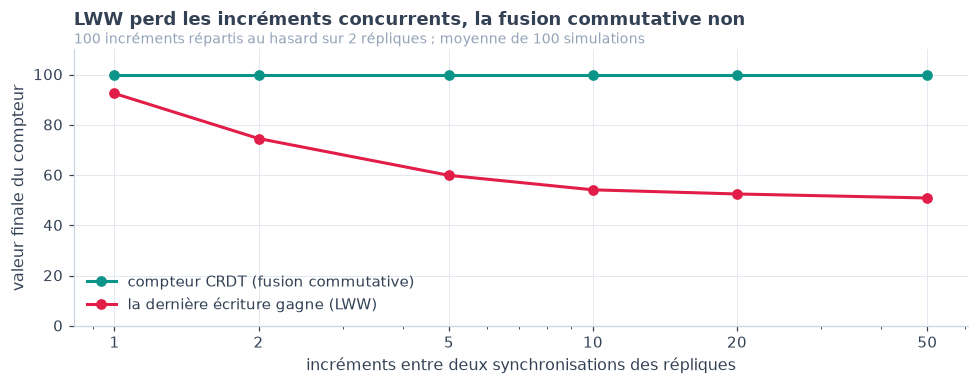

In [9]:
def repliques(n_incr, k, g):
    lww = [(0, 0.0), (0, 0.0)]        # (valeur, horodatage) par réplique
    crdt = [[0, 0], [0, 0]]           # sous-compteurs par réplique
    t = 0.0
    for i in range(n_incr):
        rep = int(g.integers(2))
        t += 1.0
        lww[rep] = (lww[rep][0] + 1, t + g.normal(0, 0.5))    # horloges légèrement décalées
        crdt[rep][rep] += 1
        if (i + 1) % k == 0:
            gagnant = max(lww, key=lambda x: x[1])
            lww = [gagnant, gagnant]
            fusion = [max(crdt[0][j], crdt[1][j]) for j in range(2)]
            crdt = [list(fusion), list(fusion)]
    gagnant = max(lww, key=lambda x: x[1])
    fusion = [max(crdt[0][j], crdt[1][j]) for j in range(2)]
    return gagnant[0], sum(fusion)


g = np.random.default_rng(4)
ks = [1, 2, 5, 10, 20, 50]
res_rep = pd.DataFrame([dict(k=k, LWW=np.mean([repliques(100, k, g)[0] for _ in range(100)]),
                             CRDT=np.mean([repliques(100, k, g)[1] for _ in range(100)])) for k in ks])
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(res_rep["k"], res_rep["CRDT"], marker="o", color=TEAL, label="compteur CRDT (fusion commutative)")
ax.plot(res_rep["k"], res_rep["LWW"], marker="o", color=ROSE, label="la dernière écriture gagne (LWW)")
ax.set_xscale("log"); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_ylim(0, 110)
ax.set_xlabel("incréments entre deux synchronisations des répliques")
ax.set_ylabel("valeur finale du compteur")
ax.set_title("LWW perd les incréments concurrents, la fusion commutative non")
subtitle(ax, "100 incréments répartis au hasard sur 2 répliques ; moyenne de 100 simulations")
ax.legend()
plt.tight_layout(); plt.show()

Le compteur CRDT finit toujours à 100. Avec LWW, plus les répliques divergent longtemps,
plus on perd : à chaque synchronisation, les incréments d'une des deux répliques sont
jetés. (Même avec $k = 1$, des horloges légèrement décalées font perdre quelques
incréments.) Les écritures conditionnelles, elles, ne peuvent pas être rendues
commutatives : on y reviendra avec la linéarisabilité au chapitre 9.

> **À retenir.** Avec plusieurs copies modifiables, on ne verrouille plus : on fusionne.
> La fusion est sans perte pour les opérations commutatives ; LWW perd des écritures.